In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("noobyogi0100/shoe-dataset")

print("Path to dataset files:", path)

/home/acheaditya/adityapython/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 324M/324M [00:50<00:00, 6.67MB/s] 

Extracting files...


Path to dataset files: /home/acheaditya/.cache/kagglehub/datasets/noobyogi0100/shoe-dataset/versions/1


In [2]:
import os
print(os.listdir(path))

['shoeTypeClassifierDataset']


In [ ]:
print(path)
print(os.listdir(path))

for root, dirs, files in os.walk(path):
    print(root, " | folders:", dirs, " | files:", len(files))

In [7]:
DATASET_PATH = "/home/acheaditya/.cache/kagglehub/datasets/noobyogi0100/shoe-dataset/versions/1/shoeTypeClassifierDataset"

print(os.listdir(DATASET_PATH))

['training', 'validation']


In [8]:
import pandas as pd

image_paths = []
labels = []

for split in ["training", "validation"]:
    split_path = os.path.join(DATASET_PATH, split)

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                image_paths.append(
                    os.path.join(class_path, filename)
                )
                labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())

Total images: 1793

Images per class:
label
boots           299
sandals         299
loafers         299
sneakers        299
flip_flops      299
soccer_shoes    298
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

In [ ]:
train_df,temp_df = train_test_split(df,test_size=0.30,stratify=df["label"],random_state=42)

In [11]:
val_df,test_df=train_test_split(temp_df,test_size=0.50,stratify=temp_df["label"],random_state=42)

In [12]:
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 1255
Validation: 269
Testing: 269


In [13]:
print("TRAINING")
print(train_df["label"].value_counts())
print("VALIDATION")
print(val_df["label"].value_counts())
print("TESTING")
print(test_df["label"].value_counts())

TRAINING
label
flip_flops      210
sandals         209
loafers         209
sneakers        209
soccer_shoes    209
boots           209
Name: count, dtype: int64
VALIDATION
label
soccer_shoes    45
sneakers        45
loafers         45
sandals         45
boots           45
flip_flops      44
Name: count, dtype: int64
TESTING
label
sandals         45
boots           45
sneakers        45
loafers         45
flip_flops      45
soccer_shoes    44
Name: count, dtype: int64


In [14]:
IMG_SIZE=(224,224)
BATCH_SIZE=32

In [15]:
classes=sorted(df["label"].unique())
print(classes)

['boots', 'flip_flops', 'loafers', 'sandals', 'sneakers', 'soccer_shoes']


In [16]:
class_to_index = {class_name:i for i, class_name in enumerate(classes)}
print(class_to_index)

{'boots': 0, 'flip_flops': 1, 'loafers': 2, 'sandals': 3, 'sneakers': 4, 'soccer_shoes': 5}


In [17]:
import tensorflow as tf
AUTOTUNE = tf.data.AUTOTUNE

I0000 00:00:1791662387.154107    8279 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791662387.164603    8279 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791662388.680368    8279 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791662394.415643    8279 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [18]:
train_paths = train_df["filepath"].values
train_labels = train_df["label"].map(class_to_index).values
val_paths = val_df["filepath"].values
val_labels = val_df["label"].map(class_to_index).values
test_paths = test_df["filepath"].values
test_labels = test_df["label"].map(class_to_index).values

In [19]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_image(image,channels=3,expand_animations=False)
    image = tf.image.resize(image,IMG_SIZE)
    image = tf.cast(image,tf.float32)/255.0
    return image, label

In [20]:
train_ds=tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))

E0000 00:00:1791662906.501427    8279 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [21]:
train_ds = train_ds.map(load_image,num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(load_image,num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(load_image,num_parallel_calls=AUTOTUNE)

In [22]:
train_ds = train_ds.shuffle(len(train_df),seed=42)
train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

In [23]:
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [24]:
for images, labels in train_ds.take(1):
    print("Image batch shape:",images.shape)
    print("Label batch shape:",labels.shape)
    print("Pixel minimum:",tf.reduce_min(images).numpy())
    print("Pixel maximum:",tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0


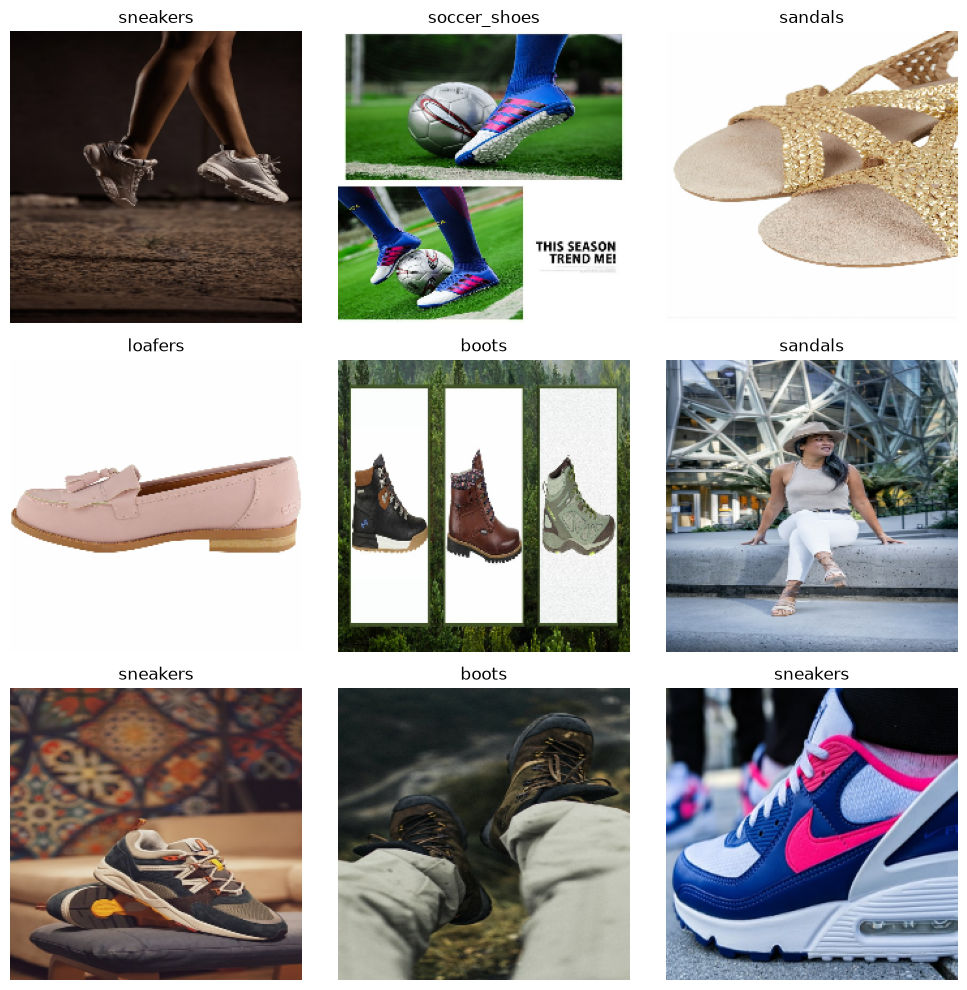

In [25]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(classes[labels[i].numpy()])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

In [28]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    tf.keras.layers.Conv2D(32,(3,3),padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64,(3,3),padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128,(3,3),padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256,(3,3),padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(6,activation="softmax")
])

In [29]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [30]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,878 (1.49 MB)

 Trainable params: 390,918 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [31]:
result=model.fit(train_ds,validation_data=val_ds,epochs=30)

Epoch 1/30


/home/acheaditya/adityapython/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


40/40 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.2980 - loss: 1.8386 - val_accuracy: 0.2416 - val_loss: 1.8620
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.3538 - loss: 1.6870 - val_accuracy: 0.2305 - val_loss: 1.8167
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.3713 - loss: 1.6180 - val_accuracy: 0.2268 - val_loss: 2.1611
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.3745 - loss: 1.5707 - val_accuracy: 0.1710 - val_loss: 2.3199
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.3976 - loss: 1.5206 - val_accuracy: 0.1673 - val_loss: 2.4718
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.3984 - loss: 1.5339 - val_accuracy: 0.2007 - val_loss: 2.0192
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.4167 - loss: 1.4713 - val_accuracy: 0.2416 - val_loss: 1.9459
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.4016 - loss: 1.5142 - val_accuracy: 0.1710 - val_loss: 2.2914
Epo

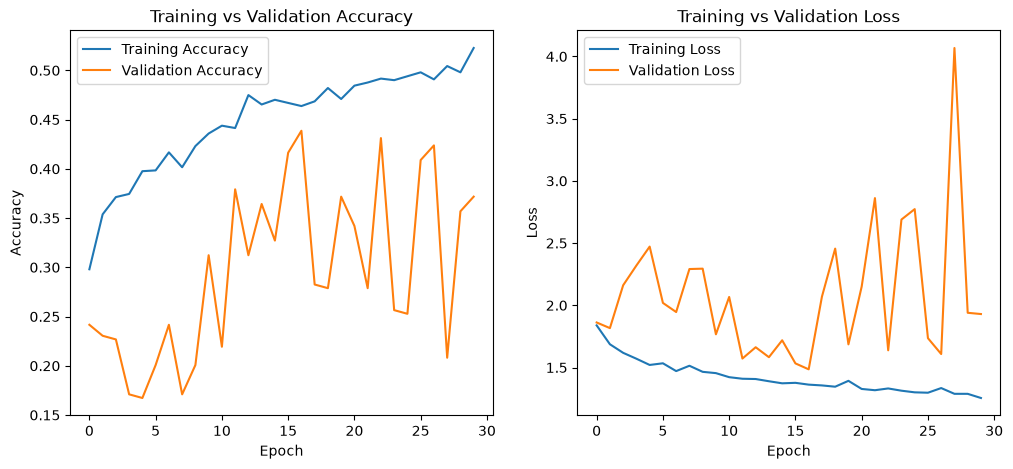

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(result.history["accuracy"], label="Training Accuracy")
plt.plot(result.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(result.history["loss"], label="Training Loss")
plt.plot(result.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [34]:
test_loss, test_accuracy=model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - accuracy: 0.4312 - loss: 1.5900
Test Loss: 1.5900176763534546
Test Accuracy: 0.4312267601490021


In [35]:
print("Best Training Accuracy:",
      max(result.history["accuracy"]))

print("Best Validation Accuracy:",
      max(result.history["val_accuracy"]))

print("Final Training Accuracy:",
      result.history["accuracy"][-1])
print("Final Validation Accuracy:",
      result.history["val_accuracy"][-1])

Best Training Accuracy: 0.5227091908454895
Best Validation Accuracy: 0.43866172432899475
Final Training Accuracy: 0.5227091908454895
Final Validation Accuracy: 0.371747225522995


In [36]:
for i in range(len(result.history["accuracy"])):
    print(
        f"Epoch {i+1}: "
        f"Train Acc = {result.history['accuracy'][i]:.3f}, "
        f"Val Acc = {result.history['val_accuracy'][i]:.3f}, "
        f"Train Loss = {result.history['loss'][i]:.3f}, "
        f"Val Loss = {result.history['val_loss'][i]:.3f}"
    )

Epoch 1: Train Acc = 0.298, Val Acc = 0.242, Train Loss = 1.839, Val Loss = 1.862
Epoch 2: Train Acc = 0.354, Val Acc = 0.230, Train Loss = 1.687, Val Loss = 1.817
Epoch 3: Train Acc = 0.371, Val Acc = 0.227, Train Loss = 1.618, Val Loss = 2.161
Epoch 4: Train Acc = 0.375, Val Acc = 0.171, Train Loss = 1.571, Val Loss = 2.320
Epoch 5: Train Acc = 0.398, Val Acc = 0.167, Train Loss = 1.521, Val Loss = 2.472
Epoch 6: Train Acc = 0.398, Val Acc = 0.201, Train Loss = 1.534, Val Loss = 2.019
Epoch 7: Train Acc = 0.417, Val Acc = 0.242, Train Loss = 1.471, Val Loss = 1.946
Epoch 8: Train Acc = 0.402, Val Acc = 0.171, Train Loss = 1.514, Val Loss = 2.291
Epoch 9: Train Acc = 0.423, Val Acc = 0.201, Train Loss = 1.465, Val Loss = 2.295
Epoch 10: Train Acc = 0.436, Val Acc = 0.312, Train Loss = 1.455, Val Loss = 1.767
Epoch 11: Train Acc = 0.444, Val Acc = 0.219, Train Loss = 1.422, Val Loss = 2.067
Epoch 12: Train Acc = 0.441, Val Acc = 0.379, Train Loss = 1.410, Val Loss = 1.572
Epoch 13: Tra

In [37]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Block 1
    tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 4
    tf.keras.layers.Conv2D(256, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(6, activation="softmax")
])

In [38]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [39]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]

In [41]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]

In [42]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


/home/acheaditya/adityapython/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


40/40 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.2837 - loss: 1.8691 - val_accuracy: 0.2156 - val_loss: 1.8053 - learning_rate: 0.0010
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.3506 - loss: 1.6154 - val_accuracy: 0.1673 - val_loss: 2.0137 - learning_rate: 0.0010
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.3785 - loss: 1.5820 - val_accuracy: 0.1673 - val_loss: 2.2814 - learning_rate: 0.0010
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.4159 - loss: 1.5063 - val_accuracy: 0.1673 - val_loss: 2.4030 - learning_rate: 5.0000e-04
